# Exploratory data analysis (report section 5)

Every analysis here is **a question, a plot, a statistic and the decision it informs** (plan §7). The notebook only calls `explorer.plots`; the same functions write the report's PDFs (`python -m explorer.cli figures`) and `reports/tables/eda_tests.csv`, so the notebook and the report never disagree. Numbers are printed from the data, not typed.

Wording rule: DS1 transactions are only ever *unusual for their own address*. "Illicit" and "ransomware" appear only as the labelled datasets' own class names.

Run it in the `cos30049-a2` environment from the `notebooks/` folder (or the repository root).

In [1]:
import os
from pathlib import Path

# The package lives in the repository root, one level up from notebooks/.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import pandas as pd
from explorer import plots

%matplotlib inline
plots.style()
pd.set_option("display.max_colwidth", 120)

FIGS = plots.available()  # every figure whose inputs exist on this machine


def show(name):
    """Draw one figure and print the statistics behind it."""
    fig, stats = FIGS[name]()
    display(fig)
    plt.close(fig)  # shown once; closing stops the inline backend drawing it a second time
    if stats:
        display(pd.DataFrame(stats)[["statistic", "value", "note"]])


sorted(FIGS)

['eda_direction_amounts',
 'eda_ds2_coverage',
 'eda_elliptic_classes',
 'eda_feature_correlation',
 'eda_feature_distributions',
 'eda_flag_rate',
 'eda_gap_ecdf',
 'eda_heist_features',
 'eda_heist_years',
 'eda_history_sizes',
 'eda_pca',
 'eda_periodicity',
 'eda_profiles',
 'eval_agreement',
 'eval_conformal',
 'eval_ds10_check',
 'eval_ds2_check',
 'eval_elliptic_f1_by_step',
 'eval_fusion_frontier',
 'eval_heist_lofo',
 'eval_injection_recall',
 'eval_label_check',
 'eval_pr_curves',
 'eval_sensitivity',
 'eval_significance',
 'eval_stages',
 'eval_txgpt_sizes',
 'eval_walkforward',
 'stats_classifiers',
 'stats_methods',
 'stats_writers']

## DS1: our Esplora snapshot (25 main and 3 short-history addresses)

### 1. How big and how long is each history?
**Decision informed:** whether a 70/30 time split per address leaves enough evaluation rows.

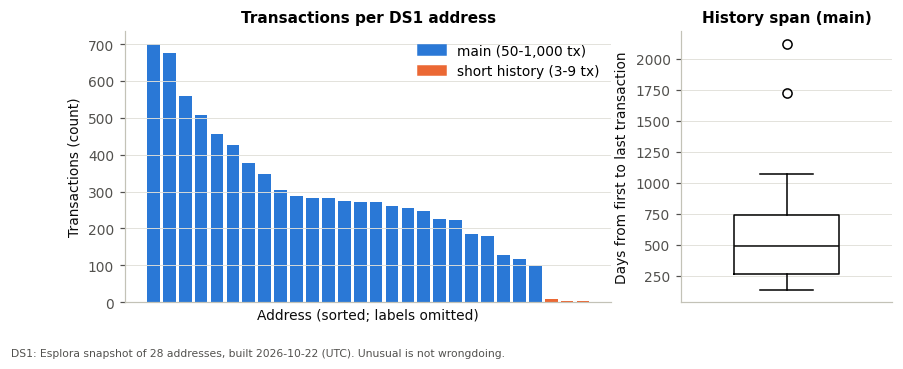

,statistic,value,note
0,median transactions per main address,274.0,
1,IQR transactions per main address,225-377,
2,"median history span (days, main)",492.1,


In [2]:
show("eda_history_sizes")

**So what.** Main addresses hold a few hundred transactions over more than a year, so the last 30% of each history gives every address a usable evaluation period (counts per address: `reports/tables/split_ds1.csv`). The three short-history addresses are kept to show the Explorer's "not enough history" state, not to score.

### 2. How are the four Explorer features distributed?
**Decision informed:** log scales, a median/MAD (robust) z-score rather than mean/SD, and a floor on the spread.

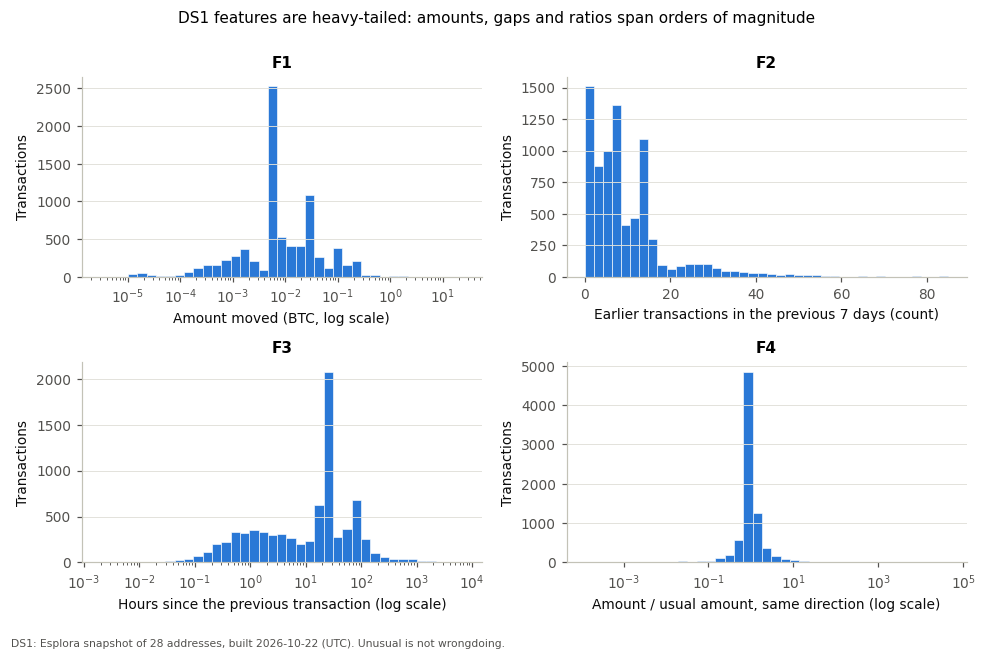

,statistic,value,note
0,F1 skewness (raw),38.89,
1,"F1 kurtosis (raw, excess)",1710.45,
2,F1 skewness (log10),-0.44,the scale the baseline compares on
3,F2 skewness (raw),2.54,
4,"F2 kurtosis (raw, excess)",9.34,
5,F3 skewness (raw),18.51,
6,"F3 kurtosis (raw, excess)",515.68,
7,F3 skewness (log10),-0.51,the scale the baseline compares on
8,F4 skewness (raw),88.19,
9,"F4 kurtosis (raw, excess)",7813.09,


In [3]:
show("eda_feature_distributions")

**So what.** F1, F3 and F4 are extremely skewed with huge kurtosis on the raw scale, and close to symmetric after a log10 transform. Means and standard deviations would be dominated by a handful of transactions, so the baseline compares on log scales with median and MAD, and F2 (a small count) stays unlogged.

### 3. Does each address have its own scale, and do its incoming and outgoing amounts differ?
**Decision informed:** per-address baselines (A1) and same-direction size comparisons (CR-04).

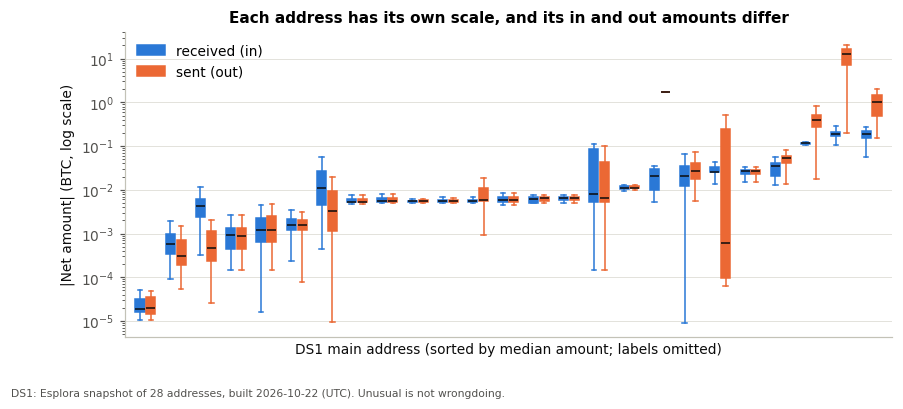

,statistic,value,note
0,addresses tested (>=5 tx each way),23.0,
1,"addresses whose in and out amounts differ (Mann-Whitney U, p<0.05)",9.0,
2,ratio of largest to smallest address median amount,9949.0,why one global threshold cannot fit every address


In [4]:
show("eda_direction_amounts")

**So what.** Median amounts differ by about four orders of magnitude between addresses, so a single global threshold cannot work: each address is compared with its own past. The direction finding is **weaker than expected**: only a minority of the tested addresses show a significant in/out difference. Same-direction comparison is still kept (it changes nothing for an address whose directions match, and it matters for those that differ), and the ablation in `eval_ablation.csv` measures its effect rather than assuming it.

### 4. Are the features redundant?
**Decision informed:** whether F1 (absolute size) and F4 (size relative to habit) both earn their place, and which extra features (F5-F8) add information.

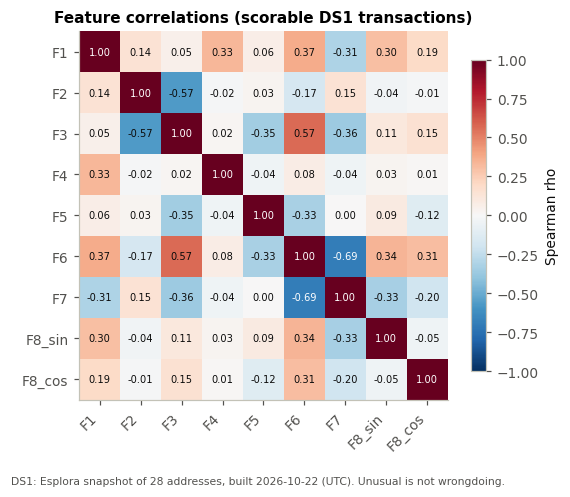

,statistic,value,note
0,rho F6-F7,-0.69,
1,rho F2-F3,-0.57,
2,rho F3-F6,0.57,
3,rho F1-F4,0.33,absolute vs habitual size


In [5]:
show("eda_feature_correlation")

**So what.** Among the four Explorer features only F2-F3 is fairly strong, and in the expected direction (busier weeks have shorter gaps); F1-F4 is moderate, so absolute size and size relative to habit each carry their own signal and both stay. The strongest link overall is among the extras (number of outputs vs fee rate), which is why F5-F8 feed only the regression models and TxGPT, never the explanations.

### 5. Is activity periodic in the day or the week?
**Decision informed:** whether the hour of day (F8) is worth testing.

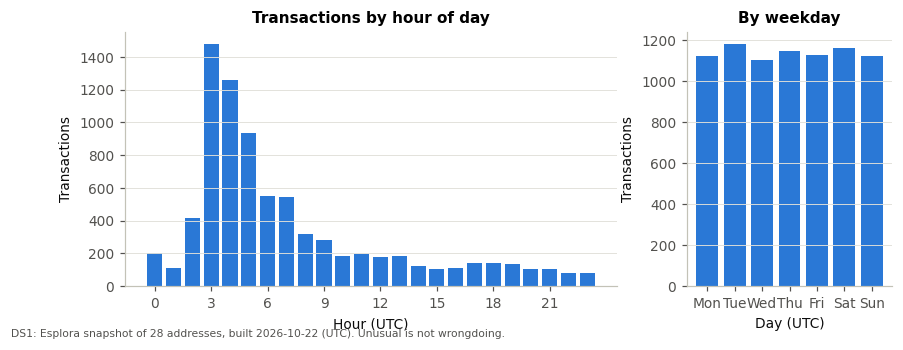

,statistic,value,note
0,chi-square vs uniform hours: p-value,0.000000,
1,chi-square vs uniform weekdays: p-value,0.728597,
2,busiest hour (UTC),3.000000,


In [6]:
show("eda_periodicity")

**So what.** Hours are far from uniform (some addresses act on a schedule), while weekdays are not distinguishable from uniform. The hour therefore enters the regression models and TxGPT as F8; the weekday does not get its own feature.

### 6. How are the gaps between transactions distributed?
**Decision informed:** TxGPT's gap buckets, and whether the planted 60-120-day dormancy is realistic.

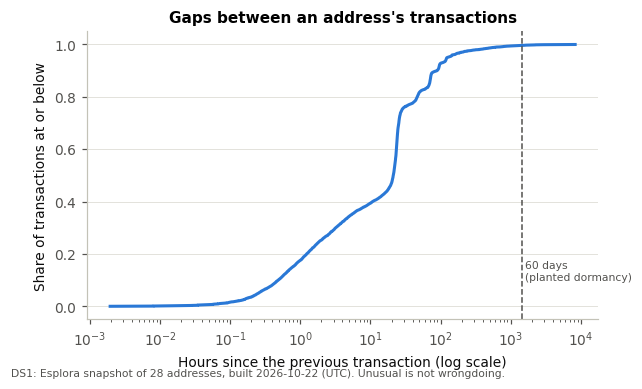

,statistic,value,note
0,gap quantile 50% (hours),21.2000,
1,gap quantile 90% (hours),89.4000,
2,gap quantile 99% (hours),618.7000,
3,share of gaps over 60 days,0.0038,


In [7]:
show("eda_gap_ecdf")

**So what.** Half of all gaps are under about a day and very few exceed 60 days, so a planted dormancy is rare in real data, as an unusual event should be. The steep step near 24 hours is scheduled daily activity. TxGPT's fixed gap buckets (`lm/tx_tokens.py`) have edges at 24 h and near the 90th and 99th percentiles (96 h and 720 h), so its gap token separates daily schedules from the rarer long gaps.

### 7. Does the z-feature space have dense groups and sparse points?
**Decision informed:** DBSCAN (density) alongside K-Means (centroids).

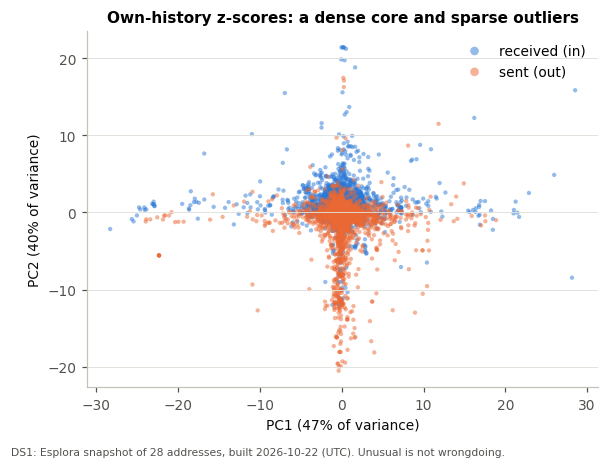

,statistic,value,note
0,explained variance PC1+PC2,0.873,
1,share of transactions within |z| radius 2,0.605,the dense core


In [8]:
show("eda_pca")

**So what.** Two components hold most of the variance; most transactions sit in a dense core near zero with sparse points far out along each axis. That shape suits density-based noise detection (DBSCAN), while K-Means' spherical clusters describe the core. Both are fitted, and both are evaluated the same way.

### 8. How many transactions break A1's |z| >= 3.5 on the raw data?
**Decision informed:** an early warning for the 20% sanity rule, and the start of the threshold sweep.

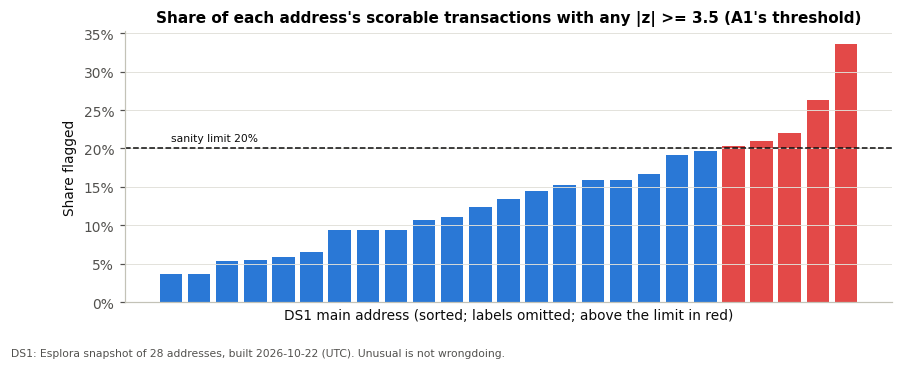

,statistic,value,note
0,overall share with |z| >= 3.5,0.139,
1,addresses above the sanity limit,5.000,led to the threshold sweep (CR-03)


In [9]:
show("eda_flag_rate")

**So what.** At A1's threshold far more than the intended ~2% of transactions are flagged, and several addresses exceed the 20% sanity limit. This led to the threshold sweep (`tuning_baseline.csv`) and to change request CR-03 for the team.

## DS3 and DS4: the labelled public datasets

### 9. How imbalanced is Elliptic, and does that change over time?
**Decision informed:** the temporal split, F1 and PR-AUC rather than accuracy, class weights.

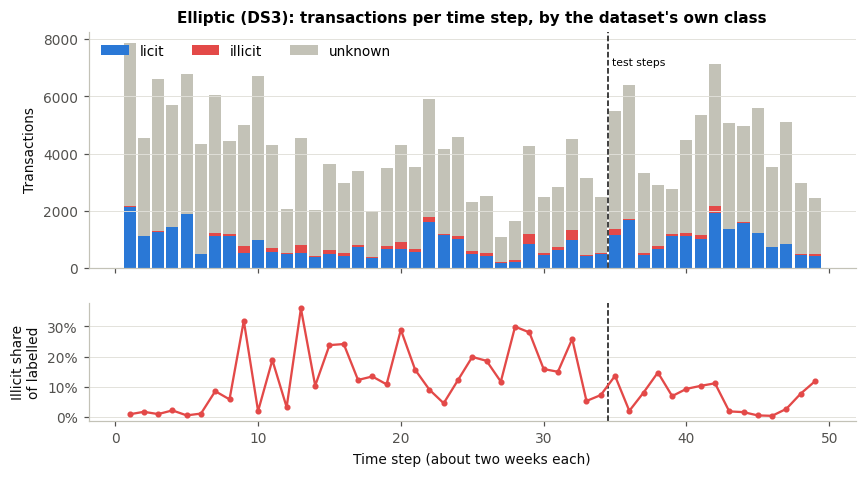

,statistic,value,note
0,"illicit share of labelled, training steps",0.1158,
1,"illicit share of labelled, test steps",0.0650,
2,unknown share of all rows,0.7710,


In [10]:
show("eda_elliptic_classes")

**So what.** Most nodes are unlabelled and the labelled illicit share moves sharply from step to step, so a random split would leak the future and accuracy would mostly reward predicting "licit". Models train on steps 1-34 and are tested once on 35-49, and they are compared by F1 and PR-AUC on the illicit class.

### 10. How imbalanced is BitcoinHeist, and in which years?
**Decision informed:** the temporal split year and which families get a leave-one-family-out test.

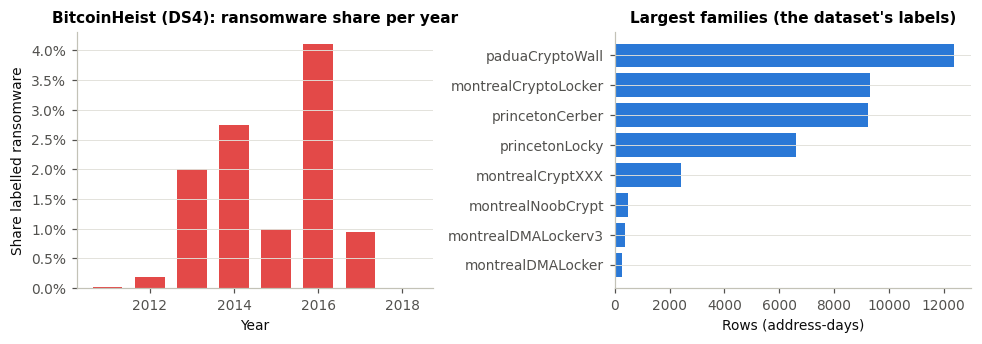

,statistic,value,note
0,overall ransomware share,0.0142,
1,highest yearly share,4.11% (2016),
2,families,28,


In [11]:
show("eda_heist_years")

**So what.** About 1.4% of rows are labelled ransomware, concentrated in a few years and a few large families. The temporal split trains up to the last year that leaves at least 1,000 positives to test, and the five largest families are each held out in turn.

### 11. Do ransomware and white rows differ on BitcoinHeist's features?
**Decision informed:** expectations for the classifiers, and how to read their results.

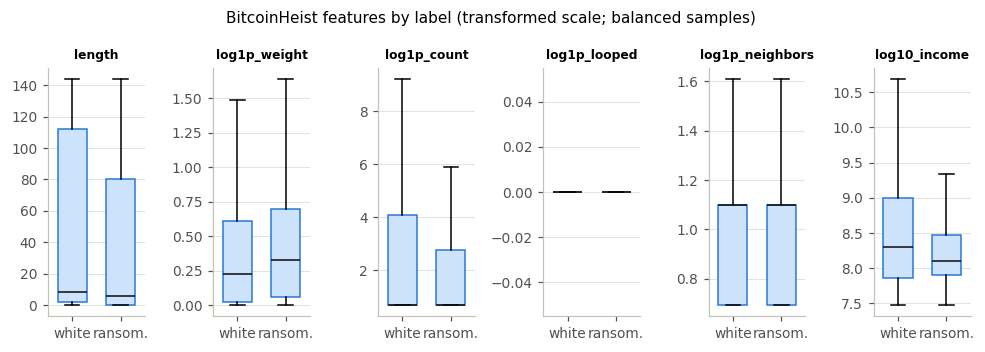

,statistic,value,note
0,length: rank-biserial effect (ransomware vs white),-0.033,Mann-Whitney p=4.6e-18; |r|<0.1 is a negligible difference
1,log1p_weight: rank-biserial effect (ransomware vs white),0.100,Mann-Whitney p=0.0e+00; |r|<0.1 is a negligible difference
2,log1p_count: rank-biserial effect (ransomware vs white),-0.011,Mann-Whitney p=1.3e-03; |r|<0.1 is a negligible difference
3,log1p_looped: rank-biserial effect (ransomware vs white),-0.037,Mann-Whitney p=0.0e+00; |r|<0.1 is a negligible difference
4,log1p_neighbors: rank-biserial effect (ransomware vs white),-0.032,Mann-Whitney p=2.2e-21; |r|<0.1 is a negligible difference
5,log10_income: rank-biserial effect (ransomware vs white),-0.127,Mann-Whitney p=0.0e+00; |r|<0.1 is a negligible difference


In [12]:
show("eda_heist_features")

**So what.** Every feature's effect size is negligible or small, even though the p-values are tiny (with this many rows any difference is "significant"). The labelled rows barely differ from the rest in these graph statistics, which predicts and explains the weak, drifting classification results below.

## Evaluation figures (report section 7)

### 12. Which DS1 method finds planted transactions?

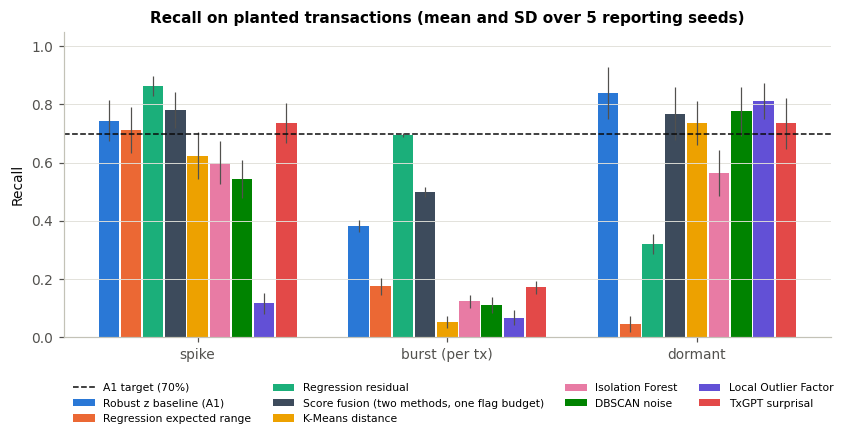

,statistic,value,note
0,baseline mean recall,0.655,
1,regression_interval mean recall,0.310,
2,regression mean recall,0.626,
3,fusion mean recall,0.682,
4,kmeans mean recall,0.470,
5,isolation_forest mean recall,0.429,
6,dbscan mean recall,0.476,
7,lof mean recall,0.331,
8,txgpt_method mean recall,0.547,


In [13]:
show("eval_injection_recall")

**So what.** No method meets the 70% target on all three patterns; the baseline, the fusion and TxGPT each meet it on two (spikes and dormancy). The A1 rule only considers methods whose stability reaches 0.7 (`eval_stability.csv`). Among those, the fusion has the highest mean recall, but within the 5-point margin of the robust-z baseline, so the baseline, the easier one to explain, is recommended (`models/selection.json`). Bursts are the hardest pattern for most methods; the regression residual is the exception, catching bursts but missing dormancy.

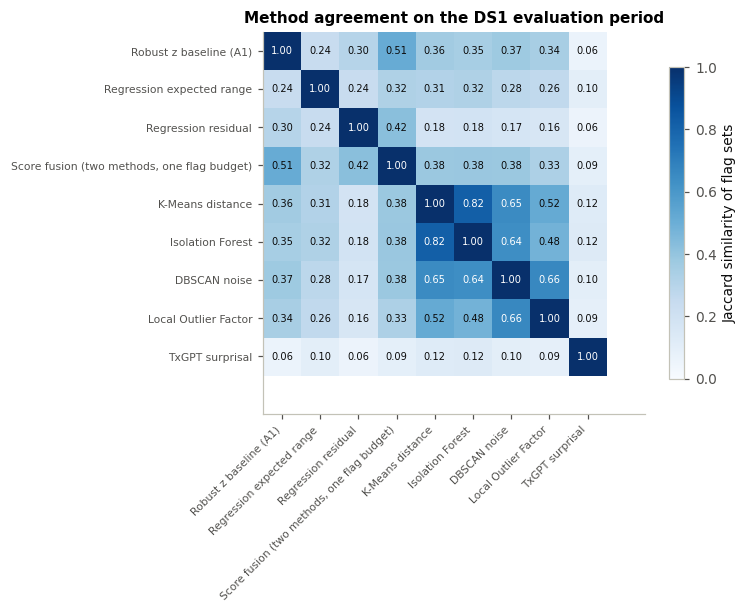

,statistic,value,note
0,median pairwise Jaccard,0.315,
1,most similar pair,isolation_forest-kmeans (0.82),


In [14]:
show("eval_agreement")

**So what.** The pooled outlier methods agree with each other far more than with the per-address baseline or the regression flags, so they largely see the same transactions; the baseline brings different ones.

### 13. Does "unusual" coincide with the labelled classes? (the label check)

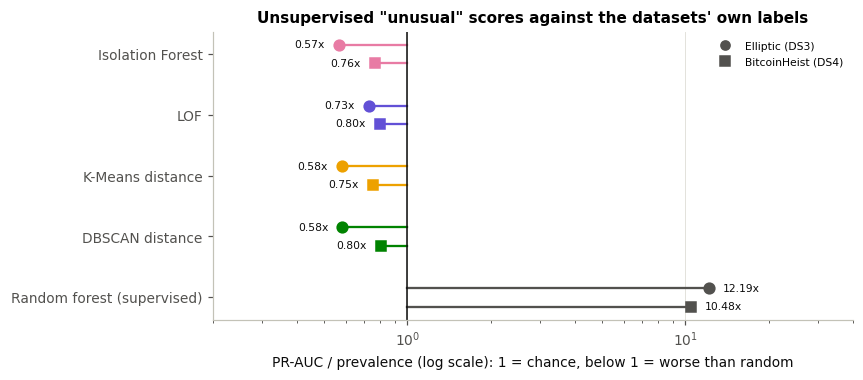

,statistic,value,note
0,elliptic_AF isolation_forest: PR-AUC / prevalence,0.565,"PR-AUC 0.0367, ROC-AUC 0.183"
1,elliptic_AF lof: PR-AUC / prevalence,0.726,"PR-AUC 0.0472, ROC-AUC 0.369"
2,elliptic_AF kmeans: PR-AUC / prevalence,0.580,"PR-AUC 0.0377, ROC-AUC 0.208"
3,elliptic_AF dbscan: PR-AUC / prevalence,0.583,"PR-AUC 0.0379, ROC-AUC 0.212"
4,elliptic_AF random_forest (supervised): PR-AUC / prevalence,12.186,"PR-AUC 0.7917, ROC-AUC 0.927"
5,heist_temporal isolation_forest: PR-AUC / prevalence,0.765,"PR-AUC 0.0038, ROC-AUC 0.410"
6,heist_temporal lof: PR-AUC / prevalence,0.796,"PR-AUC 0.0040, ROC-AUC 0.416"
7,heist_temporal kmeans: PR-AUC / prevalence,0.751,"PR-AUC 0.0038, ROC-AUC 0.404"
8,heist_temporal dbscan: PR-AUC / prevalence,0.801,"PR-AUC 0.0040, ROC-AUC 0.427"
9,heist_temporal random_forest (supervised): PR-AUC / prevalence,10.475,"PR-AUC 0.0523, ROC-AUC 0.800"


In [15]:
show("eval_label_check")

**So what.** All four unsupervised methods rank the labelled positives *below* chance on Elliptic and below chance on BitcoinHeist too, while a supervised random forest is 10-12x above chance. Labelled activity is often *typical*, not unusual. This is direct evidence for the Explorer's wording: an unusual transaction is worth a look, not a sign of wrongdoing.

### 14. The supervised models on the labelled data

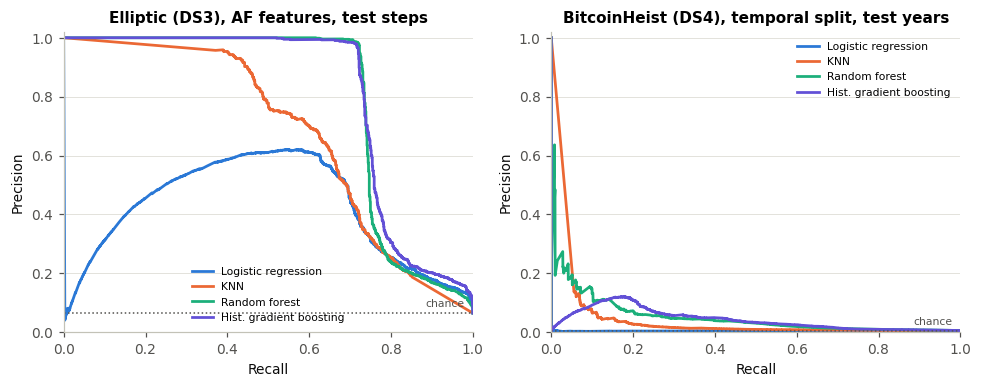

In [16]:
show("eval_pr_curves")

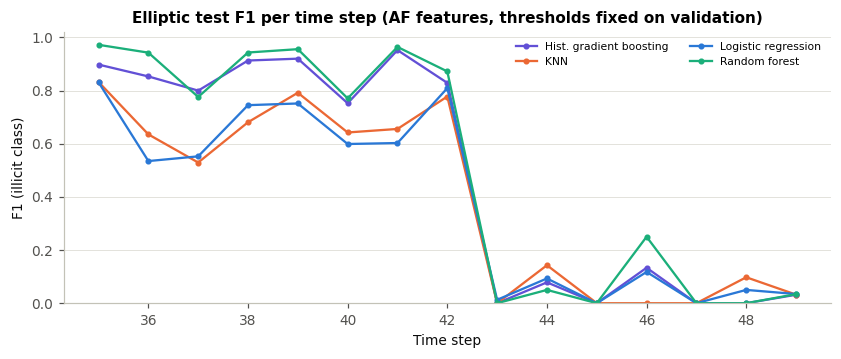

,statistic,value,note
0,"best model (randomForest) mean F1, steps 35-42",0.900,
1,"best model (randomForest) mean F1, steps 43-49",0.048,"Pareja et al. (2020) report the same collapse from step 43, after a dark-market shutdown"


In [17]:
show("eval_elliptic_f1_by_step")

**So what.** On Elliptic the tree models are strong until time step 43 and then fail for every model, the distribution shift Pareja et al. (2020) also report; one test-set F1 hides this, so the report shows both.

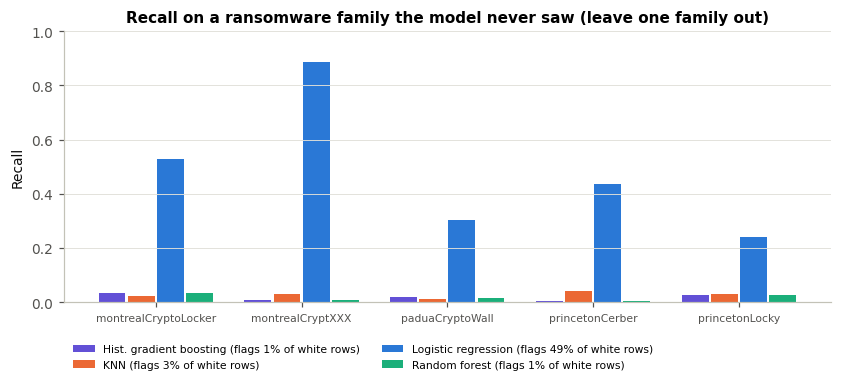

,statistic,value,note
0,histGradientBoosting: mean held-out-family recall,0.018,false-positive rate on the random split's test set 0.015
1,knn: mean held-out-family recall,0.027,false-positive rate on the random split's test set 0.033
2,logistic: mean held-out-family recall,0.479,false-positive rate on the random split's test set 0.492
3,randomForest: mean held-out-family recall,0.017,false-positive rate on the random split's test set 0.010


In [18]:
show("eval_heist_lofo")

**So what.** Models that are not simply flagging half of all rows find almost none of a family they never saw: they learn the families in the training data, not a general "ransomware behaviour". Logistic regression's high recall comes with a ~49% false-positive rate, so it is not a counter-example.